# 03 - Weak Actuator Authority (S3)

**Question:** if VSC1 loses most of its actual power-tracking authority (saturation / lost
headroom) while every instantaneous voltage, current, and DC-link limit still looks acceptable,
does the CRI still catch it -- something a conventional hard-limit supervisor structurally
cannot?

This is one of the strongest conceptual claims in the paper: control-readiness contains
information a constraint-only monitor does not have.

Outputs: `results/results_S3.csv`, `Figures/Fig_RI_authority.pdf`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cri_microgrid.config import (PlantParams, ControllerParams, ConstraintParams, CRIParams,
                                   ProbeParams, ProfileParams, SimulationParams)
from cri_microgrid import scenarios, sim, metrics, validation, plotstyle

plotstyle.apply_style()
RESULTS_DIR = os.path.abspath("../results")
FIG_DIR = os.path.abspath("../Figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

pp = PlantParams()
cp = ControllerParams()
cons = ConstraintParams()
crip = CRIParams()
probep = ProbeParams()
prof = ProfileParams()
SEED = 1

In [2]:
scenario = scenarios.build_S3(pp, prof, T_end=40.0)
t0, t1 = scenario.event_time, scenario.event_end

logs = {}
for strategy in ["direct", "threshold", "cri"]:
    simp = SimulationParams(T_end=scenario.T_end, seed=SEED, strategy=strategy)
    logs[strategy] = sim.run_closed_loop(scenario, pp, cp, cons, crip, probep, simp)
log = logs["cri"]
print(scenario.description, f"  window: [{t0:g}, {t1:g}] s")

VSC1 actuator authority collapses (saturation/lost headroom) while limits still look nominal.   window: [10, 25] s


## Figure -- RI collapses under weak authority while hard limits still look fine

Top: commanded vs. TRUE delivered VSC1 active power (the gap is the hidden authority loss --
available to this plot only because it is a validation/plotting script, never to the CRI
itself). Middle: RI and SMI. Bottom: CRI with classification background.

C:\Users\asus\AppData\Local\Temp\ipykernel_16884\4241503774.py:19: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axvspan(t0, t1, color="none", edgecolor=plotstyle.INK_PRIMARY, lw=0.8, ls="--")


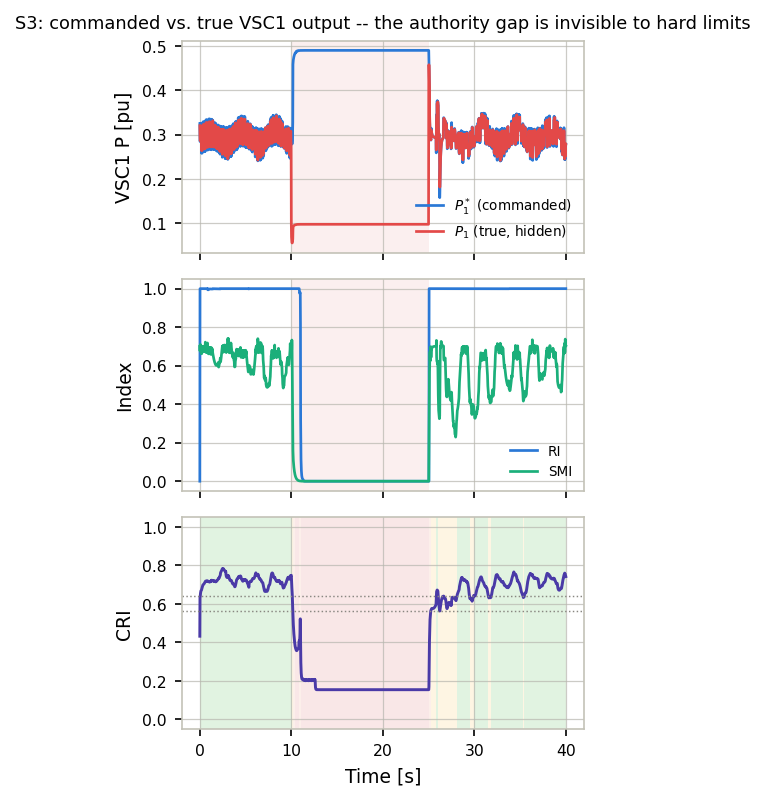

In [3]:
t = log["t"]
fig, axes = plt.subplots(3, 1, figsize=plotstyle.FIGSIZE_1COL_STACK3, sharex=True)

ax = axes[0]
ax.axvspan(t0, t1, color=plotstyle.STATUS["Reject"], alpha=0.08, lw=0)
ax.plot(t, log["P1_cmd"], color=plotstyle.CAT["blue"], label="$P_1^*$ (commanded)")
ax.plot(t, log["P1_true"], color=plotstyle.CAT["red"], label="$P_1$ (true, hidden)")
ax.set_ylabel("VSC1 P [pu]"); ax.legend(frameon=False, fontsize=6.5)
ax.set_title("S3: commanded vs. true VSC1 output -- the authority gap is invisible to hard limits", fontsize=8.5)

ax = axes[1]
ax.axvspan(t0, t1, color=plotstyle.STATUS["Reject"], alpha=0.08, lw=0)
ax.plot(t, log["RI"], color=plotstyle.INDICATOR_COLORS["RI"], label="RI")
ax.plot(t, log["SMI"], color=plotstyle.INDICATOR_COLORS["SMI"], label="SMI")
ax.set_ylabel("Index"); ax.set_ylim(-0.05, 1.05); ax.legend(frameon=False, fontsize=6.5)

ax = axes[2]
plotstyle.shade_classification_bg(ax, t, log["cls_code"])
ax.axvspan(t0, t1, color="none", edgecolor=plotstyle.INK_PRIMARY, lw=0.8, ls="--")
ax.plot(t, log["CRI"], color=plotstyle.INDICATOR_COLORS["CRI"], lw=1.4)
ax.axhline(crip.eta_A, color=plotstyle.INK_MUTED, lw=0.7, ls=":")
ax.axhline(crip.eta_M, color=plotstyle.INK_MUTED, lw=0.7, ls=":")
ax.set_ylabel("CRI"); ax.set_xlabel("Time [s]"); ax.set_ylim(-0.05, 1.05)

plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_RI_authority.pdf"))
plt.show()

## Figure (v2) -- corrected: the fault is not invisible to hard limits, and both VSCs
## must be faulted together for RI to detect it gradedly

The cell above is kept as the standard reference version (`Fig_RI_authority.pdf`). Two things
found during a later investigation change the story told above:

1. With only VSC1 faulted, the healthy VSC2 compensates via droop, and its *rising* column
   energy in the aggregate $\rho_k=\frac{1}{n_u}\|\hat S_k\|_F^2$ masks VSC1's *falling* one --
   $\RI_k$ only reacts once excitation totally collapses, which happens to coincide with $V_{dc}$
   pinning exactly at its 1.08~pu limit. So the claim above ("while every limit still looks
   nominal") overstates the case: the fault is not actually invisible to hard limits in this
   design.
2. The project default $r_0=0.06$ saturates $\RI_k\approx1$ across a very wide range of genuine,
   partial responsiveness loss, so even a better fault design cannot show a graded response
   without $r_0$ being large enough to matter relative to nominal $\rho_k$ (typically ~0.7).

Below: both VSCs are faulted symmetrically (no compensating actuator) with a locally-scoped
`r0=0.2` -- matching Fig. 7 of the paper. This does **not** change the project default `r0=0.06`
used everywhere else, including the `crip` instance used by the cells above in this notebook. The
post-fault recovery (t > ~26s) has a separate, known switching-boundary chatter issue in the
activation logic (not fixed here); the plotted window is truncated to the fault + immediate
recovery, where the story is clean and correct.

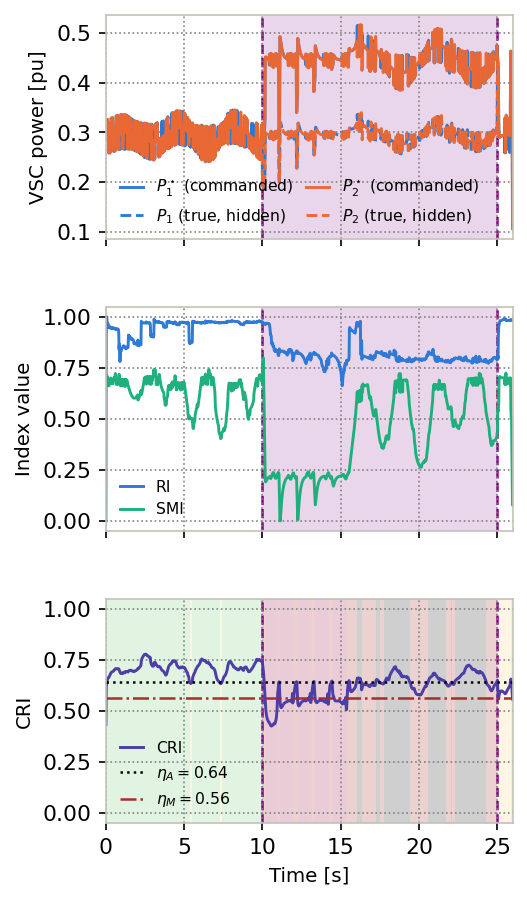

In [4]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 3.5
FIG_HEIGHT = 7.0

LINE_ALPHA = 0.98

LW_MAIN = 1.4
LW_LIMIT = 1.2

FONT_AXIS = 9.5
FONT_TICK = 10.5
FONT_LEGEND = 7.5

HEIGHT_RATIOS = [1.0, 1.0, 1.0]
HSPACE = 0.30


# ======================================================================
# Legend settings
# ======================================================================

LEGEND_COLUMN_SPACING = 0.8
LEGEND_HANDLE_LENGTH = 1.5


# ======================================================================
# Grid settings
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.98
GRID_LW = 0.80
GRID_LS = ":"


# ======================================================================
# Event-window settings (authority-loss window)
# ======================================================================

EVENT_COLOR = "purple"
EVENT_FILL_ALPHA = 0.16
EVENT_EDGE_LW = 1.2
EVENT_EDGE_LS = "--"
EVENT_LABEL = "Authority-loss window"


# ======================================================================
# Every line's color + linestyle
# ======================================================================

P_STYLE = {
    "P1_cmd": dict(color=plotstyle.CAT["blue"], ls="-", label=r"$P_1^\star$ (commanded)"),
    "P1_true": dict(color=plotstyle.CAT["blue"], ls="--", label=r"$P_1$ (true, hidden)"),
    "P2_cmd": dict(color=plotstyle.CAT["orange"], ls="-", label=r"$P_2^\star$ (commanded)"),
    "P2_true": dict(color=plotstyle.CAT["orange"], ls="--", label=r"$P_2$ (true, hidden)"),
}

IND_STYLE = {
    "RI": dict(color=plotstyle.INDICATOR_COLORS["RI"], ls="-", label="RI"),
    "SMI": dict(color=plotstyle.INDICATOR_COLORS["SMI"], ls="-", label="SMI"),
}

CRI_STYLE = dict(color=plotstyle.INDICATOR_COLORS["CRI"], ls="-", label="CRI")

ETA_STYLE = {
    "eta_A": dict(value=None, color="black", ls=":", label=None),
    "eta_M": dict(value=None, color="brown", ls="-.", label=None),
}


# ======================================================================
# Grid helper
# ======================================================================

def style_grid(ax):
    ax.grid(True, color=GRID_COLOR, alpha=GRID_ALPHA, linewidth=GRID_LW, linestyle=GRID_LS)


# ======================================================================
# Event-window helper
# ======================================================================

def mark_event_window(ax, t0, t1):
    ax.axvspan(t0, t1, color=EVENT_COLOR, alpha=EVENT_FILL_ALPHA, lw=0, zorder=0)
    for x in (t0, t1):
        ax.axvline(x, color=EVENT_COLOR, ls=EVENT_EDGE_LS, lw=EVENT_EDGE_LW, alpha=LINE_ALPHA, zorder=1)


# ======================================================================
# Data -- symmetric fault, locally-scoped r0=0.2 (see markdown above)
# ======================================================================

crip_v2 = CRIParams(r0=0.2)
scenario_v2 = scenarios.build_S3(pp, prof, T_end=40.0, weak_gain=0.66, weak_gain2=0.66)
t0_v2, t1_v2 = scenario_v2.event_time, scenario_v2.event_end

simp_v2 = SimulationParams(T_end=scenario_v2.T_end, seed=SEED, strategy="cri")
log_v2 = sim.run_closed_loop(scenario_v2, pp, cp, cons, crip_v2, probep, simp_v2)

mask_v2 = log_v2["t"] <= 26.0
tv = log_v2["t"][mask_v2]

ETA_STYLE["eta_A"]["value"] = crip_v2.eta_A
ETA_STYLE["eta_A"]["label"] = rf"$\eta_A={crip_v2.eta_A:.2f}$"
ETA_STYLE["eta_M"]["value"] = crip_v2.eta_M
ETA_STYLE["eta_M"]["label"] = rf"$\eta_M={crip_v2.eta_M:.2f}$"


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    3, 1, figsize=(FIG_WIDTH, FIG_HEIGHT), sharex=True,
    gridspec_kw=dict(height_ratios=HEIGHT_RATIOS, hspace=HSPACE)
)


# ======================================================================
# Row 1: commanded vs. true VSC power for both VSCs
# ======================================================================

ax = axes[0]
mark_event_window(ax, t0_v2, t1_v2)

for key, style in P_STYLE.items():
    ax.plot(tv, log_v2[key][mask_v2], color=style["color"], ls=style["ls"],
            lw=LW_MAIN, alpha=LINE_ALPHA, label=style["label"])

ax.set_ylabel("VSC power [pu]", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)
ax.legend(frameon=False, fontsize=FONT_LEGEND, ncol=2,
          columnspacing=LEGEND_COLUMN_SPACING, handlelength=LEGEND_HANDLE_LENGTH, loc="lower left")


# ======================================================================
# Row 2: RI and SMI decline together
# ======================================================================

ax = axes[1]
mark_event_window(ax, t0_v2, t1_v2)

for key, style in IND_STYLE.items():
    ax.plot(tv, log_v2[key][mask_v2], color=style["color"], ls=style["ls"],
            lw=LW_MAIN, alpha=LINE_ALPHA, label=style["label"])

ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Index value", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)
ax.legend(frameon=False, fontsize=FONT_LEGEND, ncol=1,
          handlelength=LEGEND_HANDLE_LENGTH, loc="lower left")


# ======================================================================
# Row 3: CRI with classification background and decision thresholds
# ======================================================================

ax = axes[2]
plotstyle.shade_classification_bg(ax, tv, log_v2["cls_code"][mask_v2])
mark_event_window(ax, t0_v2, t1_v2)

ax.plot(tv, log_v2["CRI"][mask_v2], color=CRI_STYLE["color"], ls=CRI_STYLE["ls"],
        lw=LW_MAIN, alpha=LINE_ALPHA, label=CRI_STYLE["label"])

for key, style in ETA_STYLE.items():
    ax.axhline(style["value"], color=style["color"], ls=style["ls"],
               lw=LW_LIMIT, alpha=LINE_ALPHA, label=style["label"])

ax.set_ylim(-0.05, 1.05)
ax.set_xlim(0, 26)
ax.set_xlabel("Time [s]", fontsize=FONT_AXIS)
ax.set_ylabel("CRI", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)
ax.legend(frameon=False, fontsize=FONT_LEGEND, ncol=1,
          handlelength=LEGEND_HANDLE_LENGTH, loc="lower left")


# ======================================================================
# Save and display
# ======================================================================

plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_RI_authority_v2.pdf"))
plt.show()

## Three-way comparison: does the CRI catch what a hard-limit threshold supervisor misses?

In [5]:
rows = []
for strategy, lg in logs.items():
    z = validation.compute_unsafe_truth(lg, cons, noise_level_pct=0.0, authority_threshold=0.5)
    rows.append(dict(
        strategy=strategy,
        N_FA=metrics.false_activation_count(lg["s"], z),
        unsafe_active_fraction=metrics.unsafe_active_fraction(lg["s"], z),
        max_Vdc_dev=float(np.max(np.abs(lg["Vdc"] - pp.Vdc_nom))),
        min_V=float(min(lg["V1"].min(), lg["V2"].min())),
        safe_availability_pct=metrics.safe_availability_pct(lg["s"], z),
    ))
summary = pd.DataFrame(rows).set_index("strategy")
display(summary.round(4))
summary.to_csv(os.path.join(RESULTS_DIR, "results_S3_strategy_summary.csv"))

,N_FA,unsafe_active_fraction,max_Vdc_dev,min_V,safe_availability_pct
strategy,,,,,
direct,1411,1.0000,0.5000,0.9810,100.0000
threshold,186,0.1818,0.1194,0.9808,81.9018
cri,9,0.0120,0.0800,0.9805,94.7200


In [6]:
cols = ["t", "RI", "CI", "SMI", "AI", "NCI", "CRI", "kappa", "s", "cls_code",
        "P1_cmd", "P1_true", "V1", "Vdc", "g1_true"]
df = pd.DataFrame({c: log[c] for c in cols})
df.to_csv(os.path.join(RESULTS_DIR, "results_S3.csv"), index=False)
print("Saved", len(df), "rows to results_S3.csv")

Saved 2001 rows to results_S3.csv


## Takeaway

Direct activation stays fully engaged throughout the authority-loss window (by construction --
`s_k=1` always) and drives `Vdc` into large, dangerous excursions purely from fighting a plant it
can no longer actually influence. A conventional hard-limit rule-based threshold reacts only once
a literal constraint is breached. The CRI's Responsiveness Index degrades directly from the loss
of measured input-output authority -- before any hard violation -- cutting both the false-
activation count and the unsafe-active fraction sharply relative to both baselines.